In [2]:
import os



def verifier_extensions(dossier):
    extensions = [".jpg", ".png", ".bmp",".jpeg"]
    invalides = []

    for racine, dossiers, fichiers in os.walk(dossier):
        for fichier in fichiers:
            ext = os.path.splitext(fichier)[1].lower()

            if ext not in extensions:
                path = os.path.join(racine, fichier)
                invalides.append(path)

    return invalides

res = verifier_extensions('../Data')

for e in res:
    os.remove(e)
    print("Supprimé :", e)




In [3]:
import cv2

path='../Data'
imgs=[]
labels=[]

for cls in os.listdir(path):
    cls_path=os.path.join(path,cls)

    if os.path.isdir(cls_path):
        for file in os.listdir(cls_path):
            pat=os.path.join(cls_path,file)

            try:
                image=cv2.imread(pat)

                if image is not None:
                    image=cv2.resize(image,(224,224))

                    imgs.append(image)
                    labels.append(cls)
            except Exception as e:
                print('erreur :',path,e)




In [4]:
from collections import Counter

compteur = Counter(labels)

compteur

Counter({'notumor': 2000,
         'pituitary': 1757,
         'meningioma': 1645,
         'glioma': 1621})

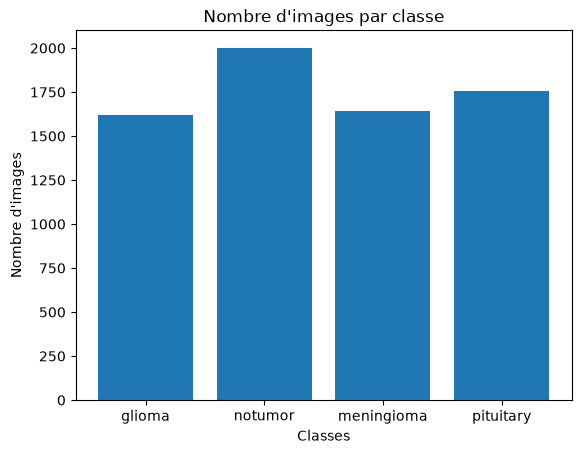

In [5]:
import matplotlib.pyplot as plt

plt.bar(compteur.keys(), compteur.values())
plt.xlabel("Classes")
plt.ylabel("Nombre d'images")
plt.title("Nombre d'images par classe")
plt.show()

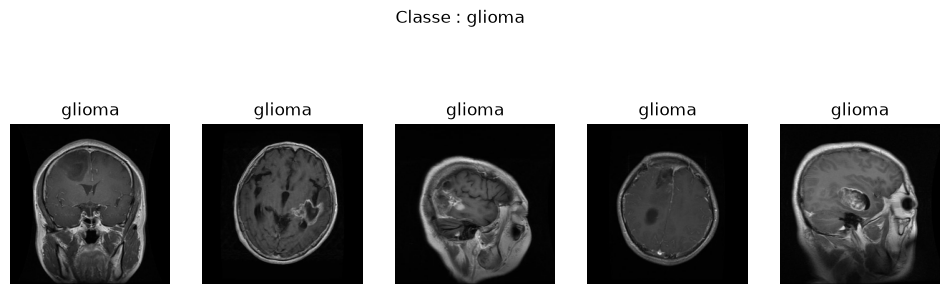

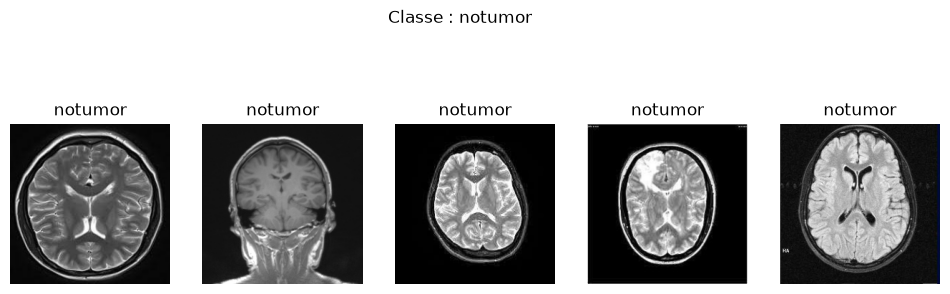

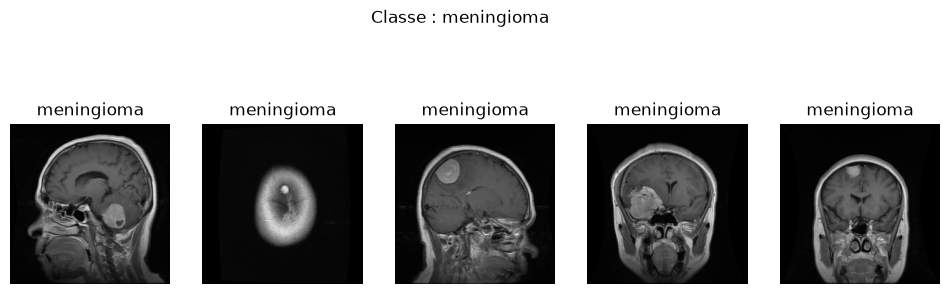

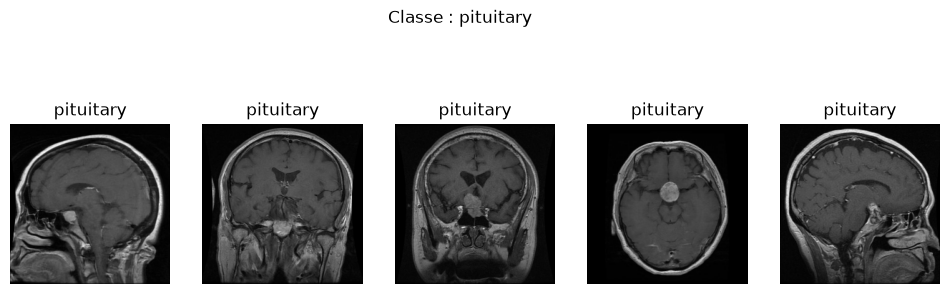

In [6]:
import matplotlib.pyplot as plt
import random

for classe in set(labels):
    indices = [i for i in range(len(labels)) if labels[i] == classe]
    indices = random.sample(indices, min(5, len(indices)))

    plt.figure(figsize=(12, 4))

    for i, index in enumerate(indices):
        plt.subplot(1, 5, i + 1)
        plt.imshow(imgs[index][:, :, ::-1])
        plt.title(labels[index])
        plt.axis("off")

    plt.suptitle("Classe : " + classe)
    plt.show()

In [7]:
from sklearn.preprocessing import LabelEncoder

prep = LabelEncoder()

lbs = prep.fit_transform(labels)
lbs

array([0, 0, 0, ..., 3, 3, 3], shape=(7023,))

In [8]:
from sklearn.model_selection import train_test_split
import numpy as np
x_train,x_test,y_train,y_test = train_test_split(
    imgs,
    lbs,
    test_size=0.2,
    random_state=42,
    stratify=lbs
)

x_train = np.array(x_train,dtype=np.uint8)
x_test = np.array(x_test,dtype=np.uint8)




In [9]:
from tensorflow.keras import layers,models 

model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),
    layers.Rescaling(1./255),

    # Data Augmentation
    layers.RandomRotation(0.04),
    layers.RandomZoom(0.1),

    # Bloc 1
    layers.Conv2D(32, 3, padding="same"),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D(),

    # Bloc 2
    layers.Conv2D(64, 3, padding="same"),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D(),

    # Bloc 3
    layers.Conv2D(128, 3, padding="same"),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D(),

    # Classification
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.4),
    layers.Dense(len(prep.classes_), activation="softmax")
])





In [10]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)




In [15]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    x_train,
    y_train,
    epochs=30,
    batch_size=4,
    validation_split=0.15,
    callbacks=[early_stop]
)

Epoch 1/30
1194/1194 ━━━━━━━━━━━━━━━━━━━━ 30s 25ms/step - accuracy: 0.7994 - loss: 0.5303 - val_accuracy: 0.8019 - val_loss: 0.6295
Epoch 2/30
1194/1194 ━━━━━━━━━━━━━━━━━━━━ 31s 26ms/step - accuracy: 0.8132 - loss: 0.5084 - val_accuracy: 0.7888 - val_loss: 0.5933
Epoch 3/30
1194/1194 ━━━━━━━━━━━━━━━━━━━━ 30s 25ms/step - accuracy: 0.8124 - loss: 0.5042 - val_accuracy: 0.7782 - val_loss: 0.6005
Epoch 4/30
1194/1194 ━━━━━━━━━━━━━━━━━━━━ 30s 25ms/step - accuracy: 0.8115 - loss: 0.4993 - val_accuracy: 0.7509 - val_loss: 0.6518
Epoch 5/30
1194/1194 ━━━━━━━━━━━━━━━━━━━━ 31s 26ms/step - accuracy: 0.8138 - loss: 0.5019 - val_accuracy: 0.7046 - val_loss: 0.9448
Epoch 6/30
1194/1194 ━━━━━━━━━━━━━━━━━━━━ 30s 25ms/step - accuracy: 0.8084 - loss: 0.5080 - val_accuracy: 0.8019 - val_loss: 0.5157
Epoch 7/30
1194/1194 ━━━━━━━━━━━━━━━━━━━━ 29s 24ms/step - accuracy: 0.8153 - loss: 0.5008 - val_accuracy: 0.8493 - val_loss: 0.4874
Epoch 8/30
1194/1194 ━━━━━━━━━━━━━━━━━━━━ 29s 24ms/step - accuracy: 0.8230 -

In [ ]:

# history = model.fit(
#     x_train,
#     y_train,
#     epochs=30,
#     batch_size=4,
#     validation_split=0.15
# )

Epoch 1/30


I0000 00:00:1792245223.701799   43108 cuda_dnn.cc:461] Loaded cuDNN version 92700


1194/1194 ━━━━━━━━━━━━━━━━━━━━ 36s 26ms/step - accuracy: 0.5313 - loss: 1.1022 - val_accuracy: 0.6560 - val_loss: 0.9081
Epoch 2/30
1194/1194 ━━━━━━━━━━━━━━━━━━━━ 30s 25ms/step - accuracy: 0.5805 - loss: 1.0088 - val_accuracy: 0.5113 - val_loss: 1.2208
Epoch 3/30
1194/1194 ━━━━━━━━━━━━━━━━━━━━ 30s 25ms/step - accuracy: 0.6126 - loss: 0.9576 - val_accuracy: 0.7153 - val_loss: 0.7322
Epoch 4/30
1194/1194 ━━━━━━━━━━━━━━━━━━━━ 30s 25ms/step - accuracy: 0.6274 - loss: 0.9006 - val_accuracy: 0.7200 - val_loss: 0.7357
Epoch 5/30
1194/1194 ━━━━━━━━━━━━━━━━━━━━ 30s 25ms/step - accuracy: 0.6444 - loss: 0.8744 - val_accuracy: 0.6121 - val_loss: 0.9751
Epoch 6/30
1194/1194 ━━━━━━━━━━━━━━━━━━━━ 30s 25ms/step - accuracy: 0.6484 - loss: 0.8510 - val_accuracy: 0.7046 - val_loss: 0.7026
Epoch 7/30
1194/1194 ━━━━━━━━━━━━━━━━━━━━ 30s 25ms/step - accuracy: 0.6666 - loss: 0.8223 - val_accuracy: 0.7212 - val_loss: 0.7355
Epoch 8/30
1194/1194 ━━━━━━━━━━━━━━━━━━━━ 30s 25ms/step - accuracy: 0.6796 - loss: 0.79

In [16]:
model.evaluate(x_test, y_test)




44/44 ━━━━━━━━━━━━━━━━━━━━ 2s 34ms/step - accuracy: 0.8413 - loss: 0.4087


[0.40869566798210144, 0.8412811160087585]

44/44 ━━━━━━━━━━━━━━━━━━━━ 2s 34ms/step


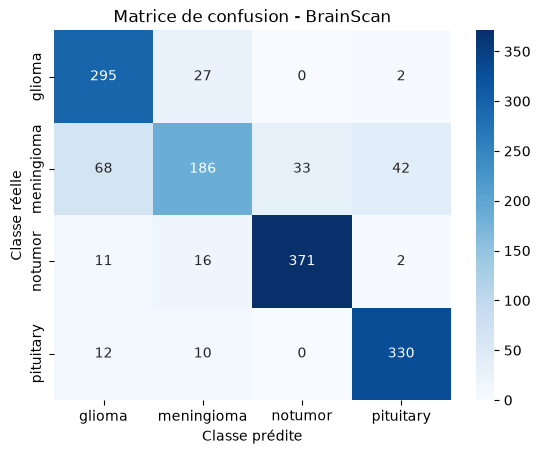

              precision    recall  f1-score   support

      glioma       0.76      0.91      0.83       324
  meningioma       0.78      0.57      0.65       329
     notumor       0.92      0.93      0.92       400
   pituitary       0.88      0.94      0.91       352

    accuracy                           0.84      1405
   macro avg       0.83      0.84      0.83      1405
weighted avg       0.84      0.84      0.83      1405



In [17]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report


# 1. Faire les prédictions
y_pred_prob = model.predict(x_test)

# 2. Récupérer la classe prédite
y_pred = np.argmax(y_pred_prob, axis=1)

# 3. Créer la matrice de confusion
cm = confusion_matrix(y_test, y_pred)

# 4. Afficher la matrice
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=prep.classes_,
    yticklabels=prep.classes_
)

plt.xlabel("Classe prédite")
plt.ylabel("Classe réelle")
plt.title("Matrice de confusion - BrainScan")
plt.show()

# 5. Afficher les métriques par classe
print(classification_report(
    y_test,
    y_pred,
    target_names=prep.classes_
))


In [19]:
print(confusion_matrix(y_test, y_pred))

[[295  27   0   2]
 [ 68 186  33  42]
 [ 11  16 371   2]
 [ 12  10   0 330]]


In [23]:
model.save("../models/brainscan_model.keras")